# P5 / 01: Gârleanu–Pedersen dynamic trading on the 15-minute residual signals (both windows)

Protocol: [`001_claude_p5_garleanu_pedersen_preregistration.md`](../../discussions/Dynamic_Trading_Costs/001_claude_p5_garleanu_pedersen_preregistration.md).

- **Signals:** A (fast) is the S05 s-score; B (slow) is the 5-session cumulative residual.
- **Ex-ante estimates:** each session, $B_k$ (predictive slopes) and $\phi_k$ (decay) are estimated on the previous 20 sessions.
- **Aim:** persistence-weighted, normalised to 100% stock gross, zero inside earnings windows.
- **Trading:** trade a fraction τ toward the aim each bar, with measured costs and the sector-ETF hedge.
- **Arms:** q = λ/γ ∈ {12, 90, 600}, giving τ = 0.25 / 0.10 / 0.04 per bar.

**Gates** per window and arm (α = 0.05/3):
- **G1** net bootstrap lower bound > 0 at blocks 10/20/40;
- **G2** beats 100 shuffled-forecast placebos (net return and Sharpe);
- **G3** net > 0 at 2× cost.

`EDGE_CANDIDATE` only if the same arm passes in both windows.

In [1]:
N_JOBS = -1
import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p2, p4, p5, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P5_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
CFG = p5.P5Config()
SCFG = s05.S05Config()                                         # S05 estimation (window 20, validity rules)
YEARS = {"A 2020-2025": list(range(2020, 2026)), "B 2017-2019": [2017, 2018, 2019]}   # 2026 sealed
ARMS = {f"q{int(q)}": q for q in CFG.arms}
ABLATIONS = {"noPW": "noPW", "Aonly": "A", "Bonly": "B"}       # at q90, reported only
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / "15Min_w3s"
PANEL_B = work_dir() / "results" / "p3" / "panel_15Min_2017_2019.npz"
OUT = ROOT / "notebooks" / "Dynamic_Trading_Costs" / ("01_synthetic" if SYNTHETIC else "01")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "p5"
CACHE.mkdir(parents=True, exist_ok=True)
if SYNTHETIC:
    YEARS = {"A 2025": [2025], "B 2024": [2024]}
    CFG = replace(CFG, n_placebo=6, n_boot=2000)
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
STOCKS, ETFS = sorted(ETF_OF), sorted(set(ETF_OF.values()))
EVENTS = None if SYNTHETIC else p4.edgar_earnings(STOCKS, start="2016-01-01", end="2025-12-31", verbose=False)
for name, q in ARMS.items():
    c, tau = p5.gp_rate(q); print(f"{name}: c = a/gamma = {c:.1f}, tau = {tau:.3f} per bar")
print(f"synthetic={SYNTHETIC} | placebos per arm and window = {CFG.n_placebo} | alpha = {CFG.alpha:.4f}")

q12: c = a/gamma = 3.0, tau = 0.250 per bar
q90: c = a/gamma = 9.0, tau = 0.100 per bar
q600: c = a/gamma = 24.0, tau = 0.040 per bar
synthetic=False | placebos per arm and window = 100 | alpha = 0.0167


## Per window: data, signals, ex-ante estimates, backtests, placebos, gates

A 2020-2025: panel (39064, 513), traded 501, earnings-blocked 4.98% of stock-days, signals and estimates in 35s


,mean,25%,50%,75%
B_A,0.0032,-0.0017,0.0030,0.0079
B_B,0.0010,-0.0051,0.0002,0.0076
phi_A,0.0197,0.0178,0.0193,0.0213
phi_B,0.0091,0.0082,0.0090,0.0099


15 backtests in 2.6 min; trading starts 2020-02-04


,total_return,sharpe,max_drawdown,mean_daily,days
q12 1x,-0.3198,-2.1052,0.3326,-0.0003,1485.0
q12 2x,-0.4993,-3.9441,0.4993,-0.0005,1485.0
q12 0x,0.0093,0.0606,0.0885,0.0000,1485.0
q90 1x,-0.1388,-1.1929,0.1476,-0.0001,1485.0
q90 2x,-0.2388,-2.2365,0.2391,-0.0002,1485.0
q90 0x,0.0102,0.0882,0.0499,0.0000,1485.0
q600 1x,-0.0809,-1.0153,0.0946,-0.0001,1485.0
q600 2x,-0.1144,-1.4551,0.1260,-0.0001,1485.0
q600 0x,-0.0340,-0.4193,0.0507,-0.0000,1485.0
noPW 1x,-0.1233,-1.0696,0.1434,-0.0001,1485.0


,annual_turnover_x_equity,annual_cost_pct_equity,avg_stock_gross
q12,234.816,7.050,0.824
q90,97.260,2.488,0.763
q600,26.799,0.674,0.584
noPW,98.796,2.531,0.769
Aonly,107.757,2.776,0.825
Bonly,78.436,2.011,0.680


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  33 tasks      | elapsed:  2.7min


... (4 outputs left out)

A 2020-2025 q600: 100 placebos in 7.3 min


value  percentile  p_upper  placebo_median  placebo_p95
q12  total_return -0.3198       100.0   0.0099         -0.4938      -0.4743
     sharpe       -2.1052       100.0   0.0099         -6.3728      -5.7881
q90  total_return -0.1388       100.0   0.0099         -0.2412      -0.2038
     sharpe       -1.1929       100.0   0.0099         -2.6667      -2.2473
q600 total_return -0.0809        68.0   0.3267         -0.0978      -0.0522
     sharpe       -1.0153        63.0   0.3762         -1.0804      -0.5423

,q12,q90,q600
G1_bootstrap,False,False,False
G2_vs_shuffled,True,True,False
G3_double_cost,False,False,False
pass,False,False,False


,q12,q90,q600,noPW,Aonly,Bonly
2020,-2.58,-0.71,-1.46,0.53,6.87,-9.12
2021,-3.24,-0.65,0.12,-0.79,0.69,-2.26
2022,-7.53,-2.91,-0.12,-3.08,-3.34,-0.21
2023,-9.98,-4.72,-1.81,-4.34,-3.61,-3.49
2024,-4.55,-2.87,-3.12,-2.64,-2.09,-3.71
2025,-9.23,-2.85,-1.96,-2.66,-1.65,-2.74


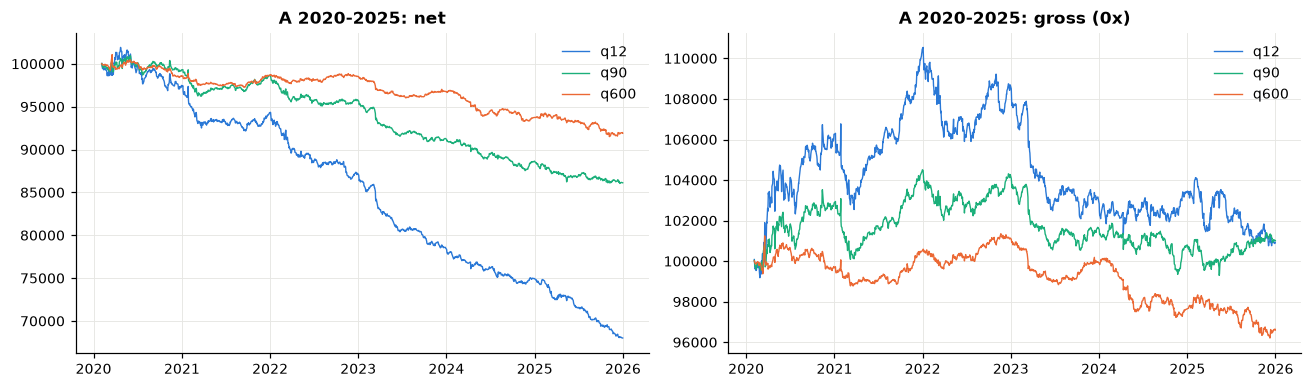

B 2017-2019: panel (19508, 492), traded 480, earnings-blocked 5.11% of stock-days, signals and estimates in 22s


,mean,25%,50%,75%
B_A,0.0064,0.0014,0.0068,0.0122
B_B,-0.0015,-0.0061,-0.0012,0.0038
phi_A,0.0208,0.0191,0.0204,0.0225
phi_B,0.0096,0.0088,0.0095,0.0105


15 backtests in 1.2 min; trading starts 2017-02-03


,total_return,sharpe,max_drawdown,mean_daily,days
q12 1x,-0.1688,-3.0558,0.1743,-0.0003,731.0
q12 2x,-0.3259,-6.6034,0.3266,-0.0005,731.0
q12 0x,0.0460,0.7288,0.0539,0.0001,731.0
q90 1x,-0.0641,-1.4390,0.0724,-0.0001,731.0
q90 2x,-0.1461,-3.5080,0.1467,-0.0002,731.0
q90 0x,0.0309,0.6616,0.0393,0.0000,731.0
q600 1x,-0.0255,-0.8427,0.0344,-0.0000,731.0
q600 2x,-0.0550,-1.8677,0.0624,-0.0001,731.0
q600 0x,0.0065,0.2179,0.0234,0.0000,731.0
noPW 1x,-0.0636,-1.4255,0.0710,-0.0001,731.0


,annual_turnover_x_equity,annual_cost_pct_equity,avg_stock_gross
q12,304.064,7.859,0.924
q90,142.076,3.335,0.836
q600,45.853,1.108,0.665
noPW,142.292,3.346,0.840
Aonly,142.898,3.367,0.881
Bonly,118.142,2.767,0.771


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  33 tasks      | elapsed:   54.4s


... (5 outputs left out)

[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  2.5min finished


value  percentile  p_upper  placebo_median  placebo_p95
q12  total_return -0.1688       100.0   0.0099         -0.3079      -0.2880
     sharpe       -3.0558       100.0   0.0099        -10.3254      -9.2871
q90  total_return -0.0641       100.0   0.0099         -0.1469      -0.1235
     sharpe       -1.4390       100.0   0.0099         -4.7997      -3.8895
q600 total_return -0.0255        97.0   0.0396         -0.0514      -0.0275
     sharpe       -0.8427        98.0   0.0297         -1.7175      -0.9800

,q12,q90,q600
G1_bootstrap,False,False,False
G2_vs_shuffled,True,True,False
G3_double_cost,False,False,False
pass,False,False,False


,q12,q90,q600,noPW,Aonly,Bonly
2017,-5.01,-1.37,-0.92,-1.46,-1.89,-1.49
2018,-5.46,-1.55,-0.12,-1.42,-1.89,-0.88
2019,-7.44,-3.60,-1.52,-3.60,-1.50,-3.08


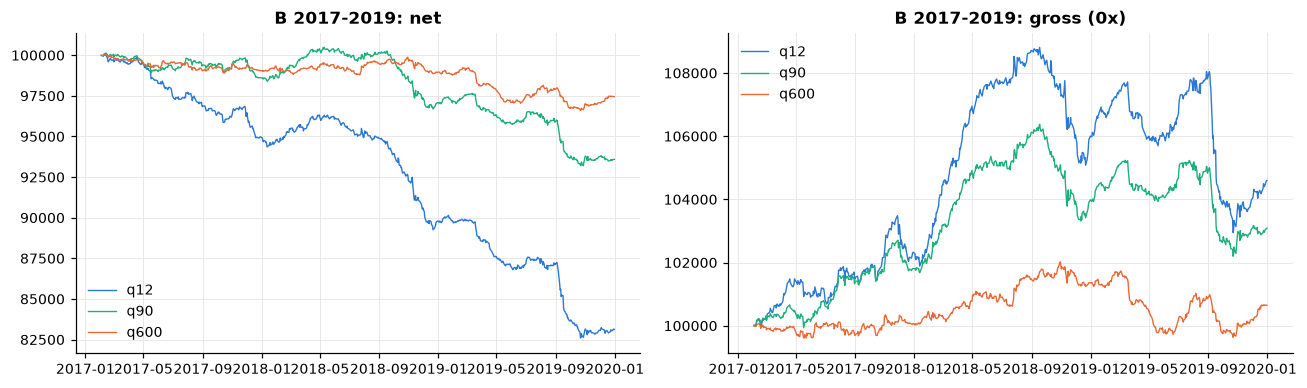

In [2]:
from joblib import Parallel, delayed
RESULTS, EST_ALL = {}, {}
for wi, (wname, years) in enumerate(YEARS.items()):
    w = wname.split()[0]
    t0 = time.time()
    if SYNTHETIC:
        panel, _ = s04.synthetic_ohlc_panel(years, seed=3 + wi)
        H = np.full(panel.c.shape, 2e-4, np.float32)
    else:
        panel = (s04.cached_panel(STOCKS + ETFS + ["SPY"], "15Min", years) if w == "A"
                 else p2.panel_cache(STOCKS + ETFS + ["SPY"], "15Min", years, PANEL_B))
        sess = s05b.sample_sessions(years, 4, seed=42)
        samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in sess], ignore_index=True)
        H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, s05b.cost_model(samples))
    have = set(panel.symbols)
    TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
    SC = np.array([panel.symbols.index(s) for s in TRADED]); EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
    tag = ("synthetic_" if SYNTHETIC else "") + f"{w}_s05{s05.S05_VERSION}_p{s04.PANEL_VERSION}"
    est_path = CACHE / f"params_{tag}.npz"
    P = dict(np.load(est_path)) if est_path.exists() else s05.estimate_all(panel, SC, EC, SCFG, s05.first_decision_day(SCFG))
    if not est_path.exists():
        np.savez(est_path, **P)
    SIG = p5.signals(panel, P, SC, EC, CFG.slow_bars)
    EST = p5.estimates(p5.day_stats(SIG, panel.n_days), CFG.est_sessions)
    EST.index = pd.to_datetime(list(panel.days)); EST_ALL[w] = EST
    days = pd.DatetimeIndex(pd.to_datetime(list(panel.days)))
    ev = p4.synthetic_events(days, TRADED, seed=11 + wi) if SYNTHETIC else EVENTS
    BLOCK = p4.event_flags(ev, days, TRADED, 1, 1).to_numpy()
    print(f"{wname}: panel {panel.c.shape}, traded {len(TRADED)}, earnings-blocked {BLOCK.mean():.2%} of stock-days, "
          f"signals and estimates in {time.time() - t0:.0f}s", flush=True)
    display(EST.describe().T[["mean", "25%", "50%", "75%"]].round(4))
    runs, rows, extra = {}, {}, {}
    t0 = time.time()
    for name, q in ARMS.items():
        for cm in (1.0, 2.0, 0.0):
            runs[(name, cm)] = p5.backtest(panel, P, SIG, EST, SC, EC, H, replace(CFG, cost_mult=cm), q, block=BLOCK)
    for name, mode in ABLATIONS.items():
        for cm in (1.0, 0.0):
            runs[(name, cm)] = p5.backtest(panel, P, SIG, EST, SC, EC, H, replace(CFG, cost_mult=cm), ARMS["q90"], mode=mode, block=BLOCK)
    START = runs[("q90", 1.0)]["first_day"]
    for (name, cm), r in runs.items():
        rows[f"{name} {cm:g}x"] = s04.perf_metrics(r["daily_equity"], CFG.initial_equity, START)
        if cm == 1.0:
            extra[name] = {k: r[k] for k in ("annual_turnover_x_equity", "annual_cost_pct_equity", "avg_stock_gross")}
    METRICS = pd.DataFrame(rows).T
    print(f"{len(runs)} backtests in {(time.time() - t0) / 60:.1f} min; trading starts {START.date()}", flush=True)
    display(METRICS.round(4)); display(pd.DataFrame(extra).T.round(3))
    G, RANKS, BOOT = {}, {}, {}
    for name, q in ARMS.items():
        pl_path = CACHE / f"placebo_{tag}_{name}_{CFG.n_placebo}.parquet"
        if pl_path.exists():
            PL = pd.read_parquet(pl_path)
        else:
            t1 = time.time()
            PL = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=1, verbose=2)(
                delayed(p5.run_placebo)(panel, P, SIG, EST, SC, EC, H, CFG, q, BLOCK, CFG.seed * 1000 + wi * 10_000 + i, START)
                for i in range(CFG.n_placebo)))
            PL.to_parquet(pl_path); print(f"{wname} {name}: {CFG.n_placebo} placebos in {(time.time() - t1) / 60:.1f} min", flush=True)
        PL.to_csv(OUT / f"placebo_{w}_{name}.csv", index=False, float_format="%.6g")
        m1 = METRICS.loc[f"{name} 1x"]
        RANKS[name] = {k: s04.placebo_rank(m1[k], PL[k].to_numpy()) for k in ("total_return", "sharpe")}
        e = runs[(name, 1.0)]["daily_equity"]; e = e[e.index >= START]
        BOOT[name] = {b: p1.block_bootstrap(e.pct_change().dropna().to_numpy(), b, CFG.n_boot, CFG.seed, CFG.alpha) for b in CFG.blocks}
        G[name] = p5.gates(BOOT[name], RANKS[name], METRICS.loc[f"{name} 2x"].to_dict(), CFG.alpha)
    for (name, cm), r in runs.items():
        if cm == 1.0:
            r["daily_equity"].to_csv(OUT / f"daily_equity_{w}_{name}.csv", header=["equity"], float_format="%.2f")
    EST.to_csv(OUT / f"estimates_{w}.csv", float_format="%.6g")
    YR = {}
    for name in list(ARMS) + list(ABLATIONS):
        e = runs[(name, 1.0)]["daily_equity"]; rr = e[e.index >= START].pct_change().dropna()
        YR[name] = rr.groupby(rr.index.year).apply(lambda x: (1 + x).prod() - 1)
    YR = pd.DataFrame(YR)
    display(pd.concat({n: pd.DataFrame(v).T for n, v in RANKS.items()}).round(4))
    display(pd.DataFrame(G)); display((100 * YR).round(2))
    RESULTS[wname] = {"metrics": METRICS.to_dict(orient="index"), "trading": extra, "ranks": RANKS,
                      "bootstrap": {n: {str(b): v for b, v in d.items()} for n, d in BOOT.items()}, "gates": G,
                      "net_by_year": {str(k): v for k, v in YR.to_dict(orient="index").items()},
                      "estimates_median": EST.median().to_dict(), "blocked_share": float(BLOCK.mean())}
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    for name, col in zip(ARMS, ("#2a78d6", "#1baf7a", "#eb6834")):
        for cm, i in ((1.0, 0), (0.0, 1)):
            e = runs[(name, cm)]["daily_equity"]; e = e[e.index >= START]
            ax[i].plot(e.index, e, color=col, lw=0.9, label=name)
    ax[0].set_title(f"{wname}: net"); ax[1].set_title(f"{wname}: gross (0x)")
    for a in ax: a.legend(frameon=False)
    plt.tight_layout(); plt.show()
    del panel, H, P, SIG, runs

## Ex-ante estimates over time, and verdict

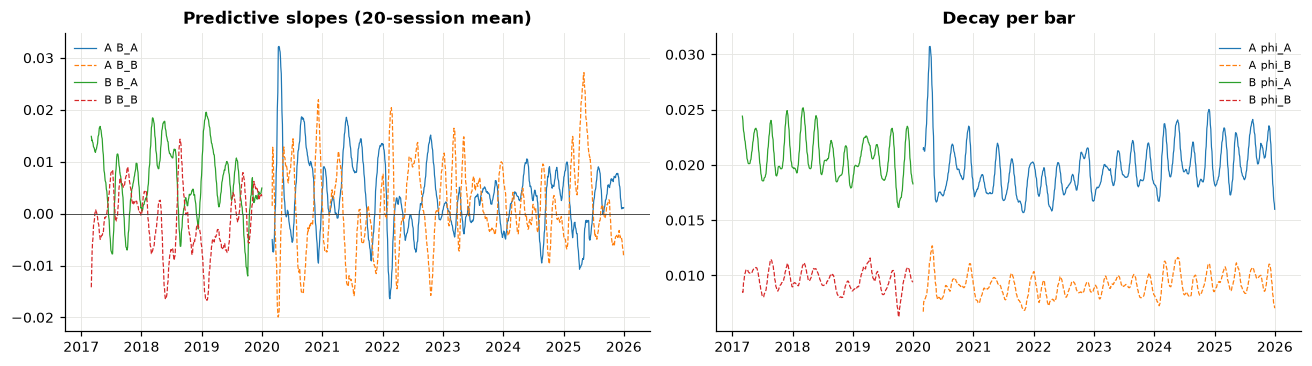

arm passes in both windows: {'q12': False, 'q90': False, 'q600': False} | verdict: NO_EDGE


666

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for w, est in EST_ALL.items():
    r = est.dropna().rolling(20).mean()
    ax[0].plot(r.index, r["B_A"], lw=0.8, label=f"{w} B_A"); ax[0].plot(r.index, r["B_B"], lw=0.8, ls="--", label=f"{w} B_B")
    ax[1].plot(r.index, r["phi_A"], lw=0.8, label=f"{w} phi_A"); ax[1].plot(r.index, r["phi_B"], lw=0.8, ls="--", label=f"{w} phi_B")
ax[0].axhline(0, color="#444", lw=0.6); ax[0].set_title("Predictive slopes (20-session mean)"); ax[1].set_title("Decay per bar")
for a in ax: a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()
both = {name: all(RESULTS[w]["gates"][name]["pass"] for w in RESULTS) for name in ARMS}
VERDICT = "EDGE_CANDIDATE" if any(both.values()) else "NO_EDGE"
print("arm passes in both windows:", both, "| verdict:", VERDICT)
summary = {"study": "P5-01", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "arms": ARMS,
           "gp_rates": {n: p5.gp_rate(q) for n, q in ARMS.items()}, "results": RESULTS, "arm_passes_both": both,
           "verdict": VERDICT, "prospective_verdict": "PENDING_2026_HOLDOUT" if VERDICT == "EDGE_CANDIDATE" else "NOT_APPLICABLE",
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "panel": s04.PANEL_VERSION, "p5": p5.P5_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))